# Graph construction in SpatialZoomer

SpatialZoomer constructs a spatial K-nearest-neighbor (KNN) graph from `adata.obsm['spatial']` before applying the spectral graph filter bank. Graph construction can be adjusted through three parameters of `sz_analyzer.multiscale_transform()`: `n_neighbors`, `metric`, and `weighting`.

```python
sz_analyzer.multiscale_transform(
    use_rep='X_nmf',
    n_neighbors=20,
    scales=scales,
    metric='euclidean',
    weighting='reciprocal',
)
```

The evaluated ranges and results below refer to the graph-construction parameter robustness analysis reported in the article.

| Parameter | Default | Main choices | Recommendation |
|---|---:|---|---|
| `n_neighbors` | `10` | Positive integers; values from `5` to `30` were evaluated | Start with `10-20`; downstream domain/niche detection was stable for `K >= 10` |
| `metric` | `'euclidean'` | `'euclidean'`, `'manhattan'`, `'chebyshev'`; other metrics supported by scikit-learn may also be specified | Use `'euclidean'` unless there is a clear reason to change the spatial geometry |
| `weighting` | `'reciprocal'` | `'reciprocal'`, `'gaussian'`, `'ranked'`, `'uniform'` | Use `'reciprocal'` as the general default |

#### Table of Contents
- [1. Number of neighbors](#1-number-of-neighbors)
- [2. Distance metric](#2-distance-metric)
- [3. Edge weighting](#3-edge-weighting)
- [4. Setup and data preprocessing](#4-setup-and-data-preprocessing)
- [5. Relationship between edge weights and physical signal diffusion](#5-relationship-between-edge-weights-and-physical-signal-diffusion)
- [6. Worked example](#6-worked-example)

## 1. Number of neighbors

`n_neighbors` sets the number of nearest spatial neighbors selected for each cell before the graph is symmetrized.

- **Smaller K:** emphasizes local structure, but may produce a less stable or poorly connected graph.
- **Larger K:** improves graph connectivity and extends the long-range, low-weight diffusion tail. An excessively large K may connect spatially unrelated cells, blur local boundaries, and increase computational cost.
- **Evaluated range:** The parameter robustness analysis reported in the article tested values from `5` to `30`. Benchmark performance was stable for `K >= 10`, whereas `K = 5` showed reduced performance.
- **Recommended range:** Start with `10-20`.

To evaluate the effect of K, change only `n_neighbors` and keep the other graph settings fixed:

```python
sz_analyzer.multiscale_transform(
    use_rep='X_nmf', n_neighbors=15, scales=scales,
    metric='euclidean', weighting='reciprocal'
)
```

## 2. Distance metric

`metric` determines how distances between spatial coordinates are measured before nearest neighbors are selected.

- `'euclidean'` (**default and recommended**): straight-line distance; appropriate for standard two- or three-dimensional spatial coordinates.
- `'manhattan'`: sum of coordinate-wise distances; useful when movement along coordinate axes is more meaningful than straight-line distance.
- `'chebyshev'`: maximum coordinate-wise distance; produces square or cubic neighborhoods.

In the parameter robustness analysis reported in the article, these three metrics produced similar critical-scale detection, physical diffusion ranges, and downstream performance. Other metrics supported by `sklearn.neighbors.NearestNeighbors` can also be specified, but were not systematically evaluated.

## 3. Edge weighting

`weighting` converts neighbor distances or ranks into graph edge weights. The weighting scheme affects signal-diffusion speed and can therefore shift numerical scale values, even when the recovered spatial structures remain similar.

| Setting | Weight definition | Interpretation | Recommendation |
|---|---|---|---|
| `'reciprocal'` | Weight is approximately proportional to `1 / (distance + epsilon)` | Emphasizes nearby neighbors and produces relatively slower diffusion | Default and recommended starting point |
| `'gaussian'` | `exp(-(distance / bandwidth)^2)` | Provides smooth distance decay using an adaptive local bandwidth | Use when smooth distance-dependent weighting is preferred |
| `'ranked'` | Gaussian-like decay based on neighbor rank | Depends on neighbor order rather than absolute coordinate distance | Use when relative neighbor order is more relevant than absolute distance |
| `'uniform'` | Equal weight for every selected neighbor | Ignores distance after the KNN set is selected | Use as a distance-independent comparison |


In the parameter robustness analysis reported in the article, all four schemes recovered comparable spatial structures and downstream performance. However, their different diffusion rates shifted the numerical scale values. With the default candidate scales, `'reciprocal'` is recommended.


## 4. Setup and data preprocessing

Import SpatialZoomer and the packages used for data preprocessing, graph inspection, and visualization.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import seaborn as sns
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,     
    "savefig.dpi": 300      
    })
use_dpi = 80 

### Load the example data

This tutorial uses the Xenium Prime mouse brain AnnData object, which can be downloaded from [Google Cloud](https://drive.google.com/file/d/1aGl5zGqxzWD5spzxpDmLPT09VOhu-Ugv/view?usp=drive_link) or from the `Tutorial1_Example_Xenium_Prime_Mouse_Brain` folder on Zenodo repository. The original data can be downloaded from [10x Genomics website](https://www.10xgenomics.com/datasets/xenium-prime-fresh-frozen-mouse-brain).  

The following cell loads `Xenium_Prime_Mouse_Brain_anndata.h5ad` using a relative path. Update the path if your directory structure differs.

In [2]:
runLabel = 'Xenium_Prime_Mouse_Brain'
save_path = './Output/' + runLabel+'_Graph_construction_test/'
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata = sc.read_h5ad("../Tutorial1_Example_Xenium_Prime_Mouse_Brain/Xenium_Prime_Mouse_Brain_anndata.h5ad")
adata

AnnData object with n_obs × n_vars = 63173 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

### Quality control and normalization

Filter cells with fewer than 10 transcripts or five detected genes, remove cells with missing nuclear area, filter genes detected in fewer than five cells, and normalize the expression matrix with `sz.Preprocess()`.

In [3]:
# Quality control on cells
sc.pp.filter_cells(adata, min_counts = 10)
sc.pp.filter_cells(adata, min_genes = 5)
adata = adata[~adata.obs['nucleus_area'].isna(), :]

# Quality control on genes
sc.pp.filter_genes(adata, min_cells = 5)

# Normalization
adata = sz.Preprocess(adata)
adata

AnnData object with n_obs × n_vars = 63022 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_counts', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p'
    obsm: 'spatial'
    layers: 'counts'

## 5. Relationship between edge weights and physical signal diffusion

Edge weights determine the relative influence transmitted between neighboring cells. Their relationship with neighbor distance helps explain how each weighting scheme affects physical signal diffusion on the graph.

The following diagnostic constructs graphs using the same cells, K, and distance metric while changing only the weighting scheme: Reciprocal, Gaussian, Uniform, or Ranked. It extracts the symmetrized edge weights, groups edges into physical-distance bins, and plots average edge weight against average neighbor distance. This comparison uses `K=15`; the worked example in Section 6 uses `K=20`. `n_bins` and `max_distance` affect only the summary plot, not graph construction.

This profile describes the local edge-weighting mechanism underlying signal diffusion; it does not directly measure the full diffusion range at each scale. For a consistent x-axis, `physical_distance` is always calculated using Euclidean distance, even when a different KNN `metric` is specified.

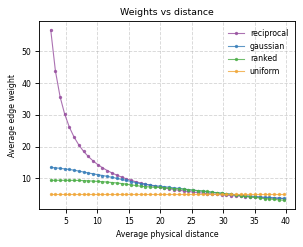

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from spatialzoomer.multiscale_analysis.Spectral_graph_filter_bank import getKNN


def compute_weighted_edges_with_spatialzoomer(
    adata, use_rep="spatial", n_neighbors=15, metric="euclidean",
    factor=100, max_similarity=None, sigma=None, pattern="auto",
    weightings=("reciprocal", "gaussian", "uniform", "ranked")
):
    """Construct SpatialZoomer KNN graphs and extract symmetrized edge weights."""
    coords = np.asarray(adata.obsm[use_rep])
    results = []

    for weighting in weightings:
        graph_key = f"__tmp_spatial_knn_{weighting}"
        max_sim = max_similarity

        if weighting == "reciprocal" and pattern == "auto" and max_sim is None:
            max_sim = 100.0

        getKNN(
            adata, use_rep=use_rep, name=graph_key,
            n_neighbors=n_neighbors, factor=factor, metric=metric,
            max_similarity=max_sim, weighting=weighting, sigma=sigma,
            pattern=pattern, results_report=False, time_report=False
        )

        graph = adata.obsp[graph_key].tocoo()
        distance = np.linalg.norm(coords[graph.row] - coords[graph.col], axis=1)

        results.append(pd.DataFrame({
            "source": graph.row,
            "target": graph.col,
            "physical_distance": distance,
            "edge_weight": graph.data,
            "weighting": weighting
        }))

        del adata.obsp[graph_key]

    return pd.concat(results, ignore_index=True)


def summarize_distance_weight(edge_df, n_bins=30, use_median=False, max_distance=None):
    """Summarize edge weights within physical-distance bins."""
    df = edge_df.copy()

    if max_distance is not None:
        df = df[df["physical_distance"] <= max_distance].copy()

    results = []
    for weighting, sub in df.groupby("weighting", observed=True):
        sub["dist_bin"] = pd.cut(sub["physical_distance"], bins=n_bins)

        g = sub.groupby("dist_bin", observed=True).agg(
            mean_physical_distance=("physical_distance", "mean"),
            median_physical_distance=("physical_distance", "median"),
            mean_edge_weight=("edge_weight", "mean"),
            median_edge_weight=("edge_weight", "median"),
            n_edges=("edge_weight", "size")
        ).reset_index(drop=True)

        g["weighting"] = weighting
        results.append(g)

    summary = pd.concat(results, ignore_index=True)

    if use_median:
        summary["x"] = summary["median_physical_distance"]
        summary["y"] = summary["median_edge_weight"]
    else:
        summary["x"] = summary["mean_physical_distance"]
        summary["y"] = summary["mean_edge_weight"]

    return summary


def plot_distance_weight_curves(summary_df, figsize=(3.8, 3.1), dpi=80):
    """Plot edge weights against physical distance."""
    order = ["reciprocal", "gaussian", "ranked", "uniform"]
    colors = ["#974F9F", "#377EB9", "#4DAE48", "#F0A73A"]

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    for weighting, color in zip(order, colors):
        sub = summary_df.query("weighting == @weighting").dropna(subset=["x", "y"]).sort_values("x")

        if not sub.empty:
            ax.plot(
                sub["x"], sub["y"], marker="o", linewidth=1,
                markersize=2, label=weighting, color=color, alpha=0.8
            )

    ax.set(
        title="Weights vs distance",
        xlabel="Average physical distance",
        ylabel="Average edge weight"
    )
    ax.legend(frameon=False)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()

    return fig, ax


edge_df = compute_weighted_edges_with_spatialzoomer(
    adata, use_rep="spatial", n_neighbors=15, metric="euclidean",
    factor=100, sigma=None, pattern="auto"
)

summary_df = summarize_distance_weight(
    edge_df, n_bins=50, use_median=False, max_distance=40
)

fig, ax = plot_distance_weight_curves(summary_df)
plt.show()

## 6. Worked example

The following baseline configuration uses Euclidean distance, Reciprocal weighting, and `K=20`:

```python
sz_analyzer.multiscale_transform(
    use_rep='X_nmf', n_neighbors=20, scales=scales,
    metric='euclidean', weighting='reciprocal'
)
```

The example below changes the distance metric and weighting scheme while keeping K and the candidate scales fixed:

```python
sz_analyzer.multiscale_transform(
    use_rep='X_nmf', n_neighbors=20, scales=scales,
    metric='manhattan', weighting='gaussian'
)
```

Because graph construction affects diffusion speed and numerical scale values, rerun critical-scale identification and downstream analyses after changing these parameters.

In [ ]:
adata = sz.performDR(adata, type = 'NMF', n_components=50)

sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path)
sz_analyzer.dpi = use_dpi

scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

Time taken to perform NMF: 305.8882 seconds


### Run the modified graph construction

The following call uses Manhattan distance and Gaussian edge weighting with `K=20`. All other transformation settings remain unchanged.

In [6]:
sz_analyzer.multiscale_transform(use_rep='X_nmf', n_neighbors=20, scales=scales, metric = 'manhattan', weighting = 'gaussian')

Median similarities:  5.0
Time taken to construct spatial_knn: 0.4401 seconds
Time taken to perform spectral graph filter bank: 36.2769 seconds
Transformed signals saved to ./Output/Xenium_Prime_Mouse_Brain_Graph_construction_test//Xenium_Prime_Mouse_Brain_transformed_signals.h5


### Recompute critical scales and clustering

Identify critical scales from the transformed signals generated with the modified graph, rerun two-step clustering, and visualize spatial and transcriptomic neighborhood homogeneity.

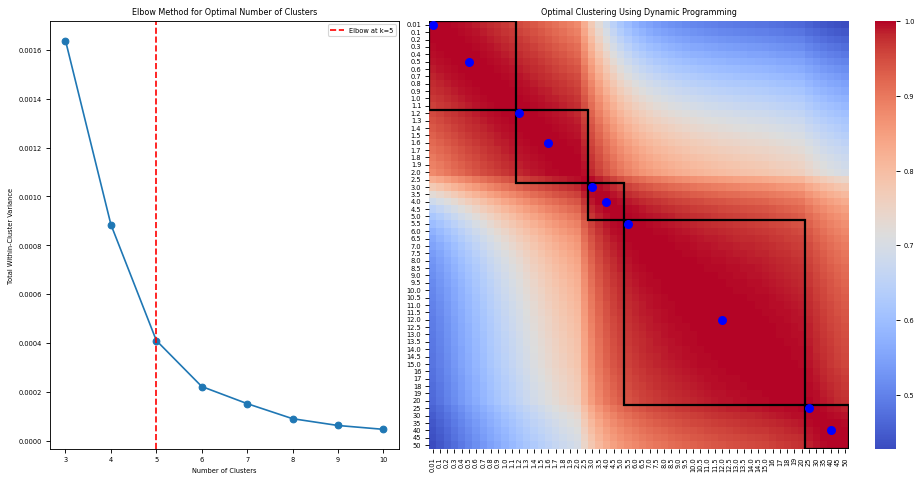

The optimal number of clusters is: 5
Typical scales: [0.01, 0.5, 1.2, 1.6, 3.0, 4.0, 5.5, 12.0, 25, 40]
Time taken to perform identification of typical scales: 7.3190 seconds
Time taken to perform UMAP and clustering for raw signal: 203.9370 seconds
Time taken to perform clustering for signal at scale 0.5: 79.3077 seconds
Time taken to perform clustering for signal at scale 1.2: 79.9040 seconds
Time taken to perform clustering for signal at scale 1.6: 89.4755 seconds
Time taken to perform clustering for signal at scale 3.0: 71.9719 seconds
Time taken to perform clustering for signal at scale 4.0: 80.0648 seconds
Time taken to perform clustering for signal at scale 5.5: 90.1665 seconds
Total time: 490.9227 seconds
Median similarities:  4.999999997312386
Time taken to construct expr_knn: 5.0853 seconds


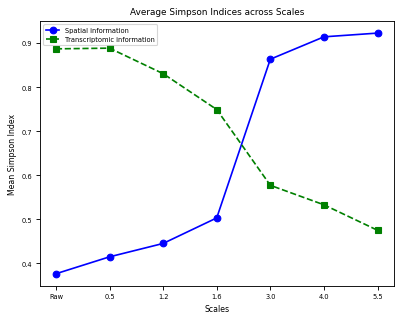

AnnData object with n_obs × n_vars = 63022 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'Kmeans_scale0.5', 'leiden_scale0.5_res0.8', 'leiden_scale0.5_res1', 'Kmeans_scale1.2', 'leiden_scale1.2_res0.8', 'leiden_scale1.2_res1', 'Kmeans_scale1.6', 'leiden_scale1.6_res0.8', 'leiden_scale1.6_res1', 'Kmeans_scale3.0', 'leiden_scale3.0_res0.8', 'leiden_scale3.0_res1', 'Kmeans_scale4.0', 'leiden_scale4.0_res0.8', 'leiden_scale4.0_res1', 'Kmeans_scale5.5', 'leiden_scale5.5_res0.8', 'leiden_scale5.5_res1'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p'
    obsm: 'spatial', 'X_nmf', 'X_umap_Raw', 'X_umap_scale0.5', 'X

In [7]:
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)
resolutions = [0.8, 1]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions, min_scale = 0.5, max_scale = 10)
sz_analyzer.plot_simpson(resolution=0.8)
sz_analyzer.adata

### Visualize and save the result

Plot clustering results across the selected scales and save the final SpatialZoomer AnnData object for downstream analysis.

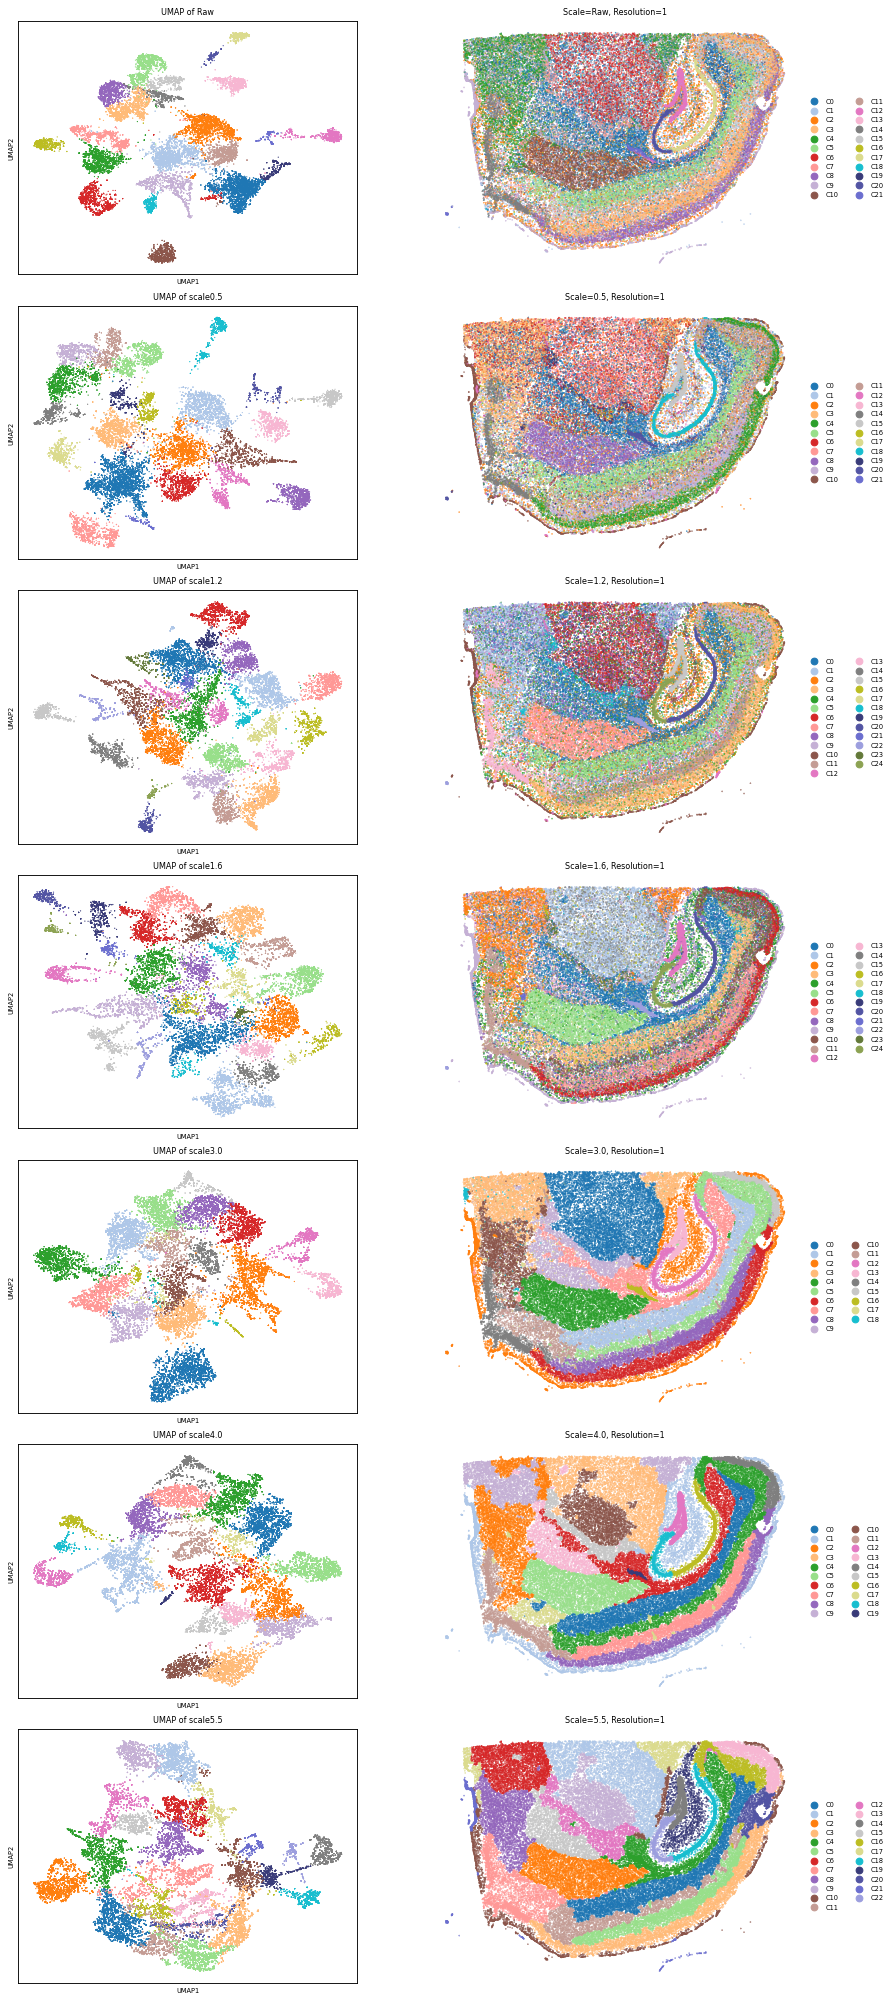

In [8]:
sz_analyzer.plot_multiscale_clusters(resolution=1, figsize=(12, 25), pt_size_scatter= 0.2)
sz_analyzer.adata.write(save_path + runLabel + '_SpatialZoomer.h5ad')